# Open water planning


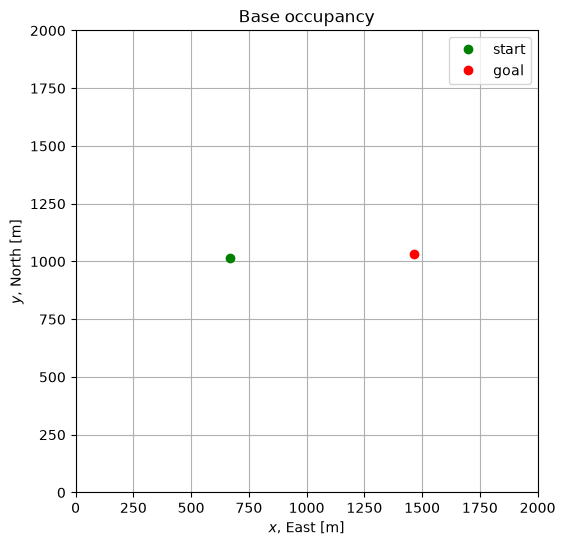

In [1]:
import matplotlib.pyplot as plt
from cartoblobpy.graph import Graph
import matplotlib.pyplot as plt
from risk_informed_planner.obstacles import *
from risk_informed_planner.visualization import *
import numpy as np


g = Graph()
g.load_from_yaml("../maps/empty/map.yaml")

obstacles = [
    LinearDynamicObstacle.create(start_pose=(1500.0, 1000.0), end_pose=(250.0, 1000.0), velocity=2.5),
]

fig, ax = plt.subplots(figsize=(6, 6))
g.plot(cmap='Grays', ax=ax)
plt.grid()

In [2]:
from risk_informed_planner.licenses import pysmile_license
from risk_informed_planner.config import Config

from risk_informed_planner.planner import RiskAwareAngleCostRRTStarSearch
from risk_informed_planner.risk.dynamic_risk import DynamicRisk
from risk_informed_planner.risk import cost_model
from risk_informed_planner.utils import Node, smooth_path

start = Node(g.start[0], g.start[1], 0)
goal = Node(g.goal[0], g.goal[1], -1)


/opt/homebrew/Caskroom/miniconda/base/envs/sandbox3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import time
import numpy as np


max_nodes = 1500
cfg = Config(
    X_LIMITS=(0, g.width),
    Y_LIMITS=(0, g.height),
    STEP_SIZE=100,
    GOAL_RADIUS=75,
    NEIGHBOR_RADIUS=200,
    MAX_NODES=max_nodes,
    MAX_NEIGHBORS_RISK_RENEWAL=max_nodes,
    ALPHA=0.1,
    BETA=100.0,
    RISK_CUTOFF=np.inf,
    GAMMA=0.5,
    MAX_TURN_ANGLE=np.pi / 4.0,
    RISK_SAMPLE_SPACING=25.0,
    RISK_AGGREGATION="mean"
)

min_depth=10.0
risk_model = DynamicRisk(
    max_distance_from_shore=10.0,
    lookahead_distance=100.0,
    graph=g,
    obstacles=obstacles,
    max_dcpa_for_collision_risk=50.0,
    max_tcpa_for_collision_risk=120.0,
    max_relative_velocity_for_collision_risk=6.0,
    grounding_depth_hard_limit=min_depth,
    desired_speed=3.0,
    cost_model=cost_model.NormalizedExpectedLoss(),
)
# cfg.RISK_CUTOFF=risk_model.cost_model.compute_worst_case_cost(risk_model.bbn_network) / 4.0


path_planner = RiskAwareAngleCostRRTStarSearch(
    start=start,
    goal=goal,
    graph=g,
    cfg=cfg,
    risk_model=risk_model,
    # callback_functions=[],
    record_bbn_snapshots=True,
    min_depth=min_depth
)


In [4]:
risk_model.cost_model.compute_worst_case_cost(risk_model.bbn_network)


1.0

In [5]:

start_time = time.perf_counter()
nodes, path = path_planner()
total_computation_time = time.perf_counter() - start_time
print(f"Planning completed in {total_computation_time:.2f} seconds.")

Progress: 100%|██████████| 1500/1500 [00:11<00:00, 129.43node/s, Path=6]

Planning completed in 11.68 seconds.


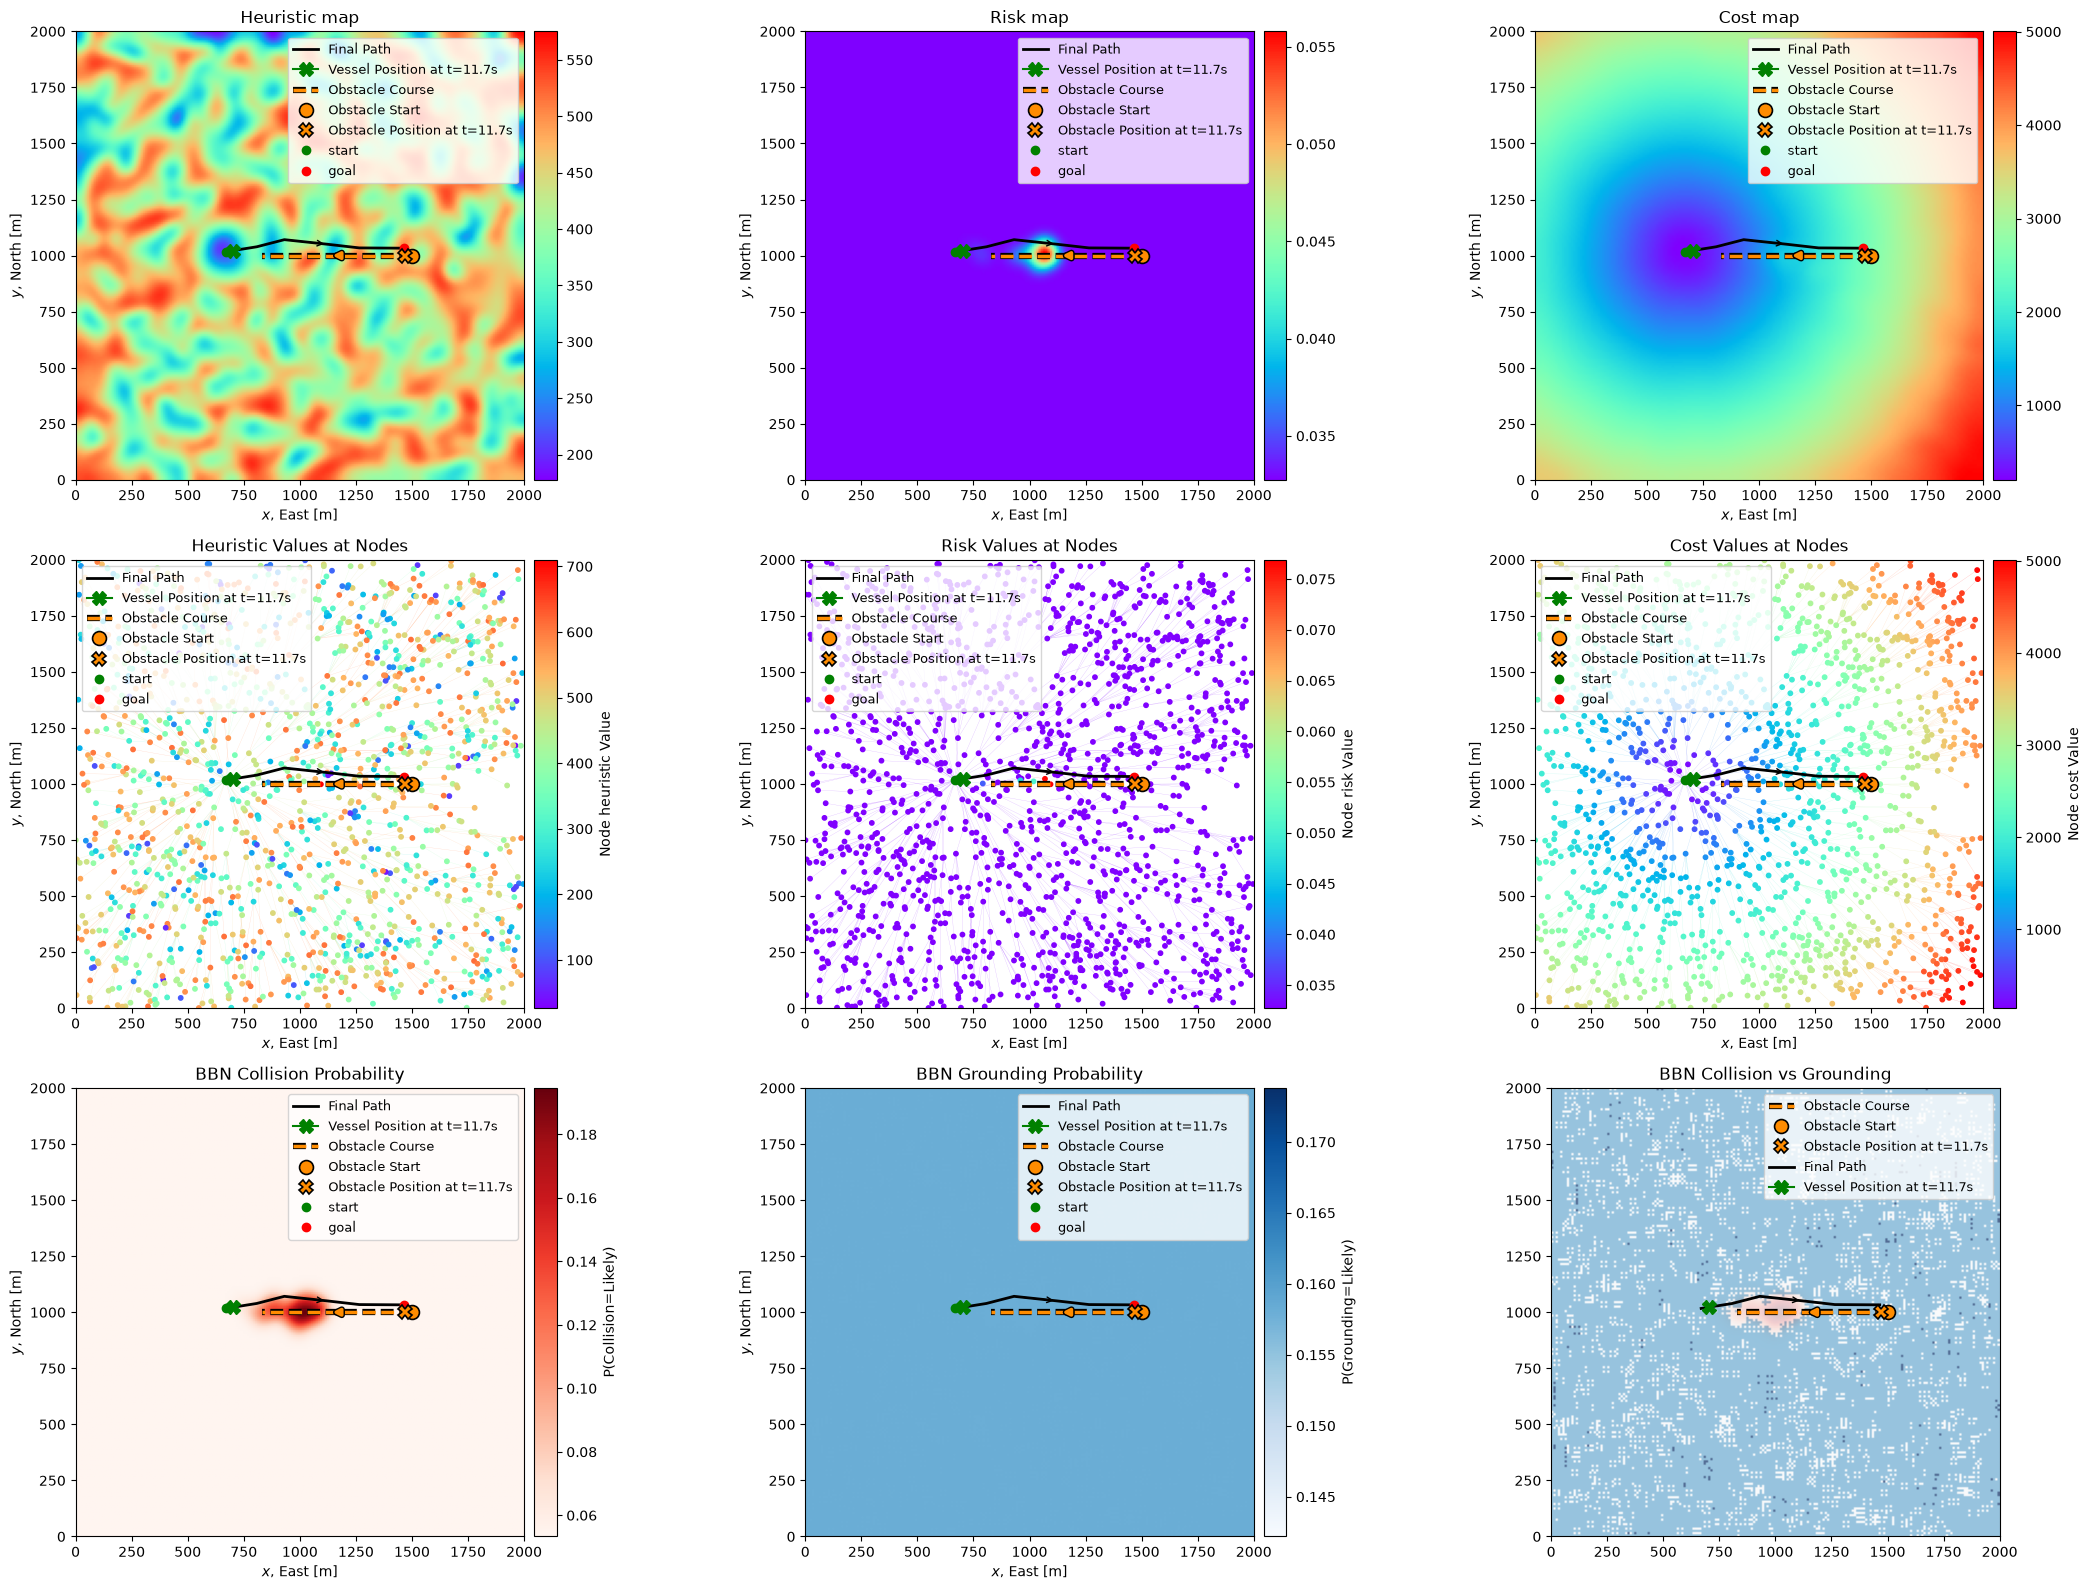

In [6]:
from risk_informed_planner.visualization import *

fig, ax = plt.subplots(3, 3, figsize=(22, 16))


axes = plot_matrix(
    nodes=nodes,
    obstacles=obstacles,
    path=path,
    cfg=cfg,
    graph=g,
    ax=ax,
    t_computation=total_computation_time,
    speed=risk_model.desired_speed
)
plt.savefig(f"plots/empty_{type(risk_model.cost_model).__name__}_alpha_{cfg.ALPHA}_beta_{cfg.BETA}.pdf")

In [7]:
nodes[120].bbn_snapshot['Grounding']

# find the node with the highest grounding probability
max_grounding_prob = 0.0
idx_of_max = 0
for idx, node in enumerate(nodes):
    try:
        grounding_prob = node.bbn_snapshot['Grounding']['values'][0]
    except KeyError:
        continue  # Skip nodes without grounding information

    if grounding_prob > max_grounding_prob:
        max_grounding_prob = grounding_prob
        idx_of_max = idx
        print(
            f"New max grounding probability found:\n "
            f"{node.bbn_snapshot['Grounding']} at node index {idx}"
        )

print(f"Node with highest grounding probability: {idx_of_max} with probability {max_grounding_prob:.4f}")

random_index = np.random.randint(1, len(nodes))
print(f"Randomly selected node index: {random_index} with grounding probability {nodes[random_index].bbn_snapshot['Grounding']['values'][0]:.4f}")

key='Vessel_on_grounding_course'
print(f"max\n"
    f"{nodes[idx_of_max].bbn_snapshot[key]}"
)
print(f"random\n"
    f"{nodes[random_index].bbn_snapshot[key]}"
)

New max grounding probability found:
 {'values': [0.1579974051759677, 0.8420025948240322], 'states': ['Likely', 'Unlikely']} at node index 1
New max grounding probability found:
 {'values': [0.15799740517596772, 0.8420025948240324], 'states': ['Likely', 'Unlikely']} at node index 276
Node with highest grounding probability: 276 with probability 0.1580
Randomly selected node index: 50 with grounding probability 0.1580
max
{'values': [1.0, 0.0], 'states': ['Yes', 'No']}
random
{'values': [1.0, 0.0], 'states': ['Yes', 'No']}


In [8]:
# how many nodes that have grounding probability above 0.4
grounding_threshold = 0.4
count_above_threshold = sum(
    1 for node in nodes
    if 'Grounding' in node.bbn_snapshot and node.bbn_snapshot['Vessel_on_grounding_course']['values'][0] > grounding_threshold
)

print(f"Number of nodes with grounding probability above {grounding_threshold}: {count_above_threshold}")

Number of nodes with grounding probability above 0.4: 1499
